SANTIAGO DIE MOREJÓN - 23/03/2026 - IA - Entregable 1 - Adicional 3 - Reducción de Dimensionalidad

# Notebook 6 - Adicional 3: Reducción de Dimensionalidad

En el notebook de visualización (notebook 2) ya aplicamos t-SNE para proyectar los datos en 2D y observamos que las clases están muy mezcladas y no son linealmente separables. Sin embargo, solo usamos una técnica con unos parámetros fijos.

En este notebook adicional vamos a explorar en profundidad las técnicas de reducción de dimensionalidad vistas en la tanto en la practica 4 como 5, aplicándolas a nuestro dataset para:


## 1. Carga de datos y librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
%config InlineBackend.figure_format = 'svg'
import warnings; warnings.simplefilter('ignore')

In [2]:
!wget -q DATA_URL -O train.csv

In [3]:
traindf = pd.read_csv('train.csv')
traindf.head()

,SL,EEG,BP,HR,CIRCULATION,ACTIVITY
0,4019.64,-1600.00,13,79,317,3
1,2191.03,-1146.08,20,54,165,2
2,2787.99,-1263.38,46,67,224,2
3,9545.98,-2848.93,26,138,554,4
4,14148.80,-2381.15,85,120,809,4


## 2. Preparación de los datos

Antes de aplicar las técnicas de reducción de dimensionalidad, separamos los descriptores de la variable objetivo y estandarizamos los datos. El escalado es importante porque PCA y t-SNE son sensibles a las diferencias de escala.

In [4]:
from sklearn.preprocessing import StandardScaler

cols = ['SL', 'EEG', 'BP', 'HR', 'CIRCULATION']
X = traindf[cols].values
y = traindf['ACTIVITY'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 3. PCA — Análisis de Componentes Principales

Como vimos en la Práctica 4 Parte 3:

* PCA (Principal Component Analysis) descompone el conjunto de datos en componentes ortogonales que explican la mayor parte de la varianza.
* Es un método de reducción lineal y eficiente.
* Las primeras componentes principales contienen gran parte de la varianza.
* Es sensible a la escala de los descriptores.


In [5]:
from sklearn.decomposition import PCA

### 3.1 Varianza explicada

En la práctica usamos la función `drawVarianza` para ver cuántas componentes necesitamos para conservar el 99% de la varianza.

In [7]:
pca_full = PCA()
pca_full.fit(X_scaled)

PCA()

In [8]:
var_exp = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var_exp)

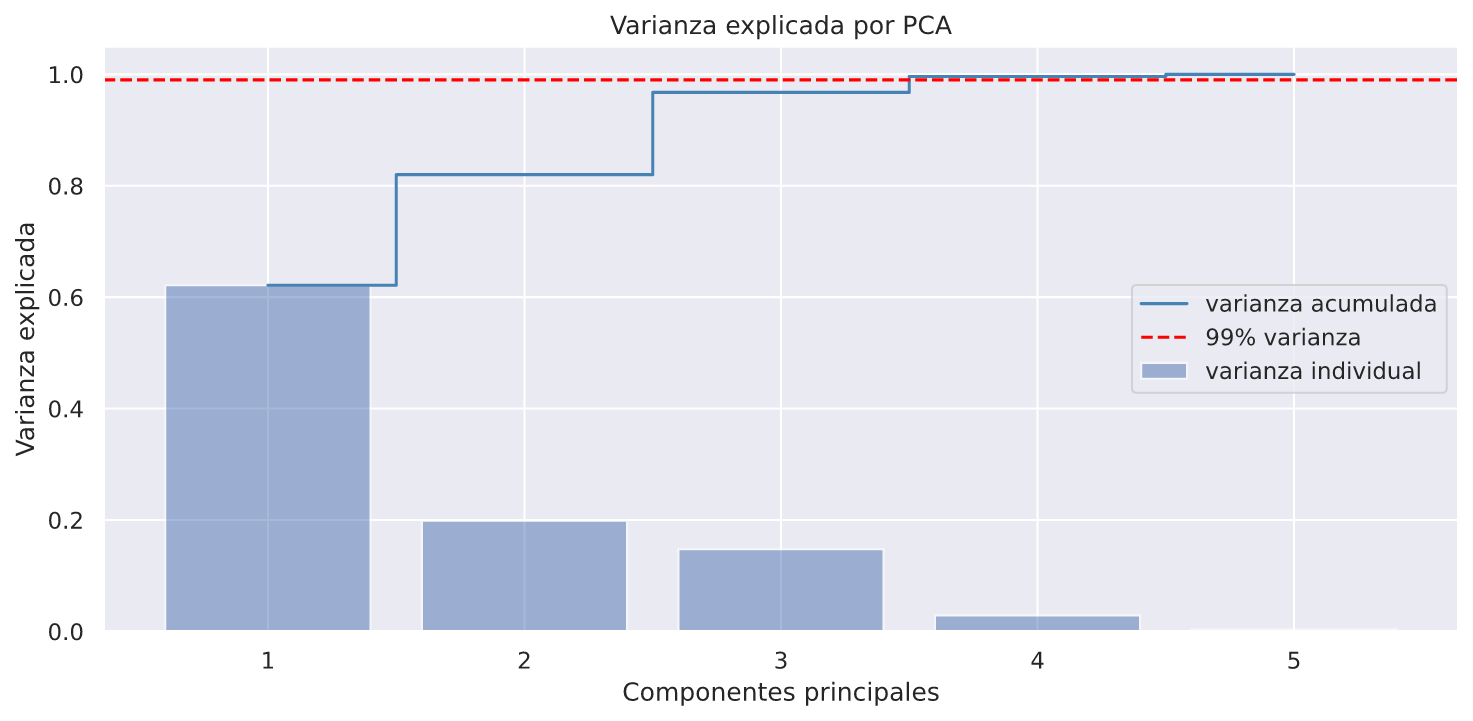

Varianza total (1 componentes): 62.14%
Varianza total (2 componentes): 81.99%
Varianza total (3 componentes): 96.76%
Varianza total (4 componentes): 99.62%
Varianza total (5 componentes): 100.00%


In [10]:
plt.figure(figsize=(10, 5))
plt.step(range(1, len(var_exp)+1), var_acum, where='mid', label='varianza acumulada', color='steelblue')
plt.bar(range(1, len(var_exp)+1), var_exp, alpha=0.5, align='center', label='varianza individual')
plt.axhline(y=0.99, color='red', linestyle='--', label='99% varianza')
plt.xlabel('Componentes principales')
plt.ylabel('Varianza explicada')
plt.title('Varianza explicada por PCA')
plt.xticks(range(1, len(var_exp)+1))
plt.legend()
plt.tight_layout()
plt.show()

for i, (v, a) in enumerate(zip(var_exp, var_acum)):
    print("Varianza total (%d componentes): %.2f%%" % (i+1, 100*a))

Siguiendo el criterio de la práctica necesitamos 4 componentes para superar el 99% (99.62%). La reducción es pequeña, de 5 a 4.

La primera componente ya explica el 62.14% de la varianza, lo cual tiene sentido porque SL, HR y CIRCULATION están altamente correlacionados y PCA comprime esa redundancia en un solo eje.

Con solo 2 componentes conservamos el 81.99%, lo que significa que la proyección 2D pierde casi un 18% de la información.

### 3.2 PCA en 2D

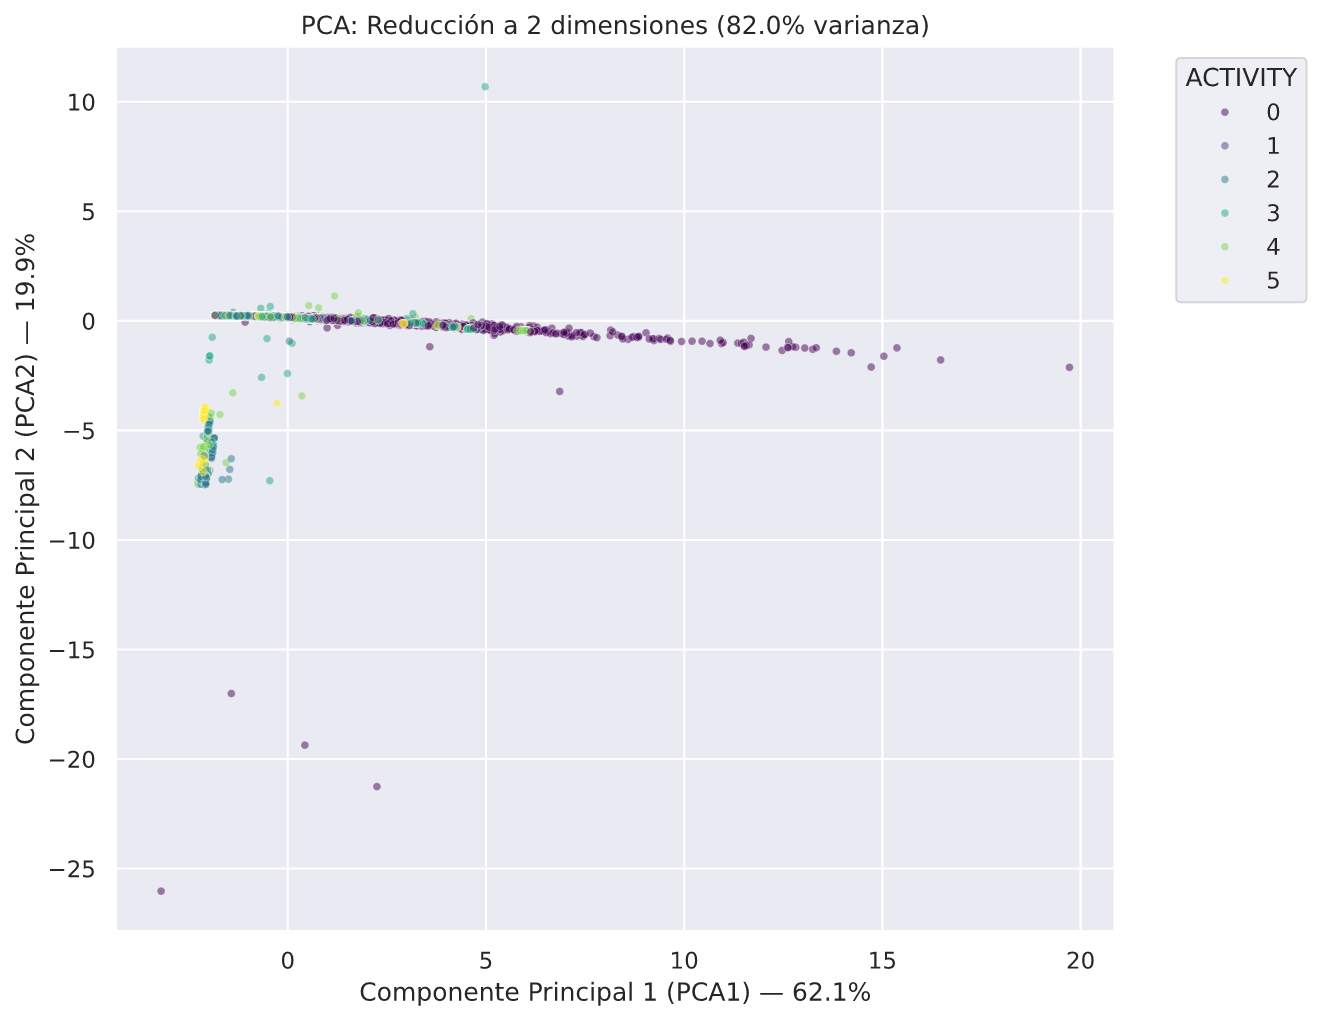

In [11]:
pca_2d = PCA(n_components=2)
X_pca2d = pca_2d.fit_transform(X_scaled)

pca_df = pd.DataFrame({'PCA1': X_pca2d[:, 0], 'PCA2': X_pca2d[:, 1], 'ACTIVITY': y})

plt.figure(figsize=(9, 7))
sns.scatterplot(x='PCA1', y='PCA2', hue='ACTIVITY', data=pca_df, palette='viridis', alpha=0.5, s=15)
plt.title('PCA: Reducción a 2 dimensiones (%.1f%% varianza)' % (100*pca_2d.explained_variance_ratio_.sum()))
plt.xlabel('Componente Principal 1 (PCA1) — %.1f%%' % (100*pca_2d.explained_variance_ratio_[0]))
plt.ylabel('Componente Principal 2 (PCA2) — %.1f%%' % (100*pca_2d.explained_variance_ratio_[1]))
plt.legend(title='ACTIVITY', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 3.3 PCA en 3D

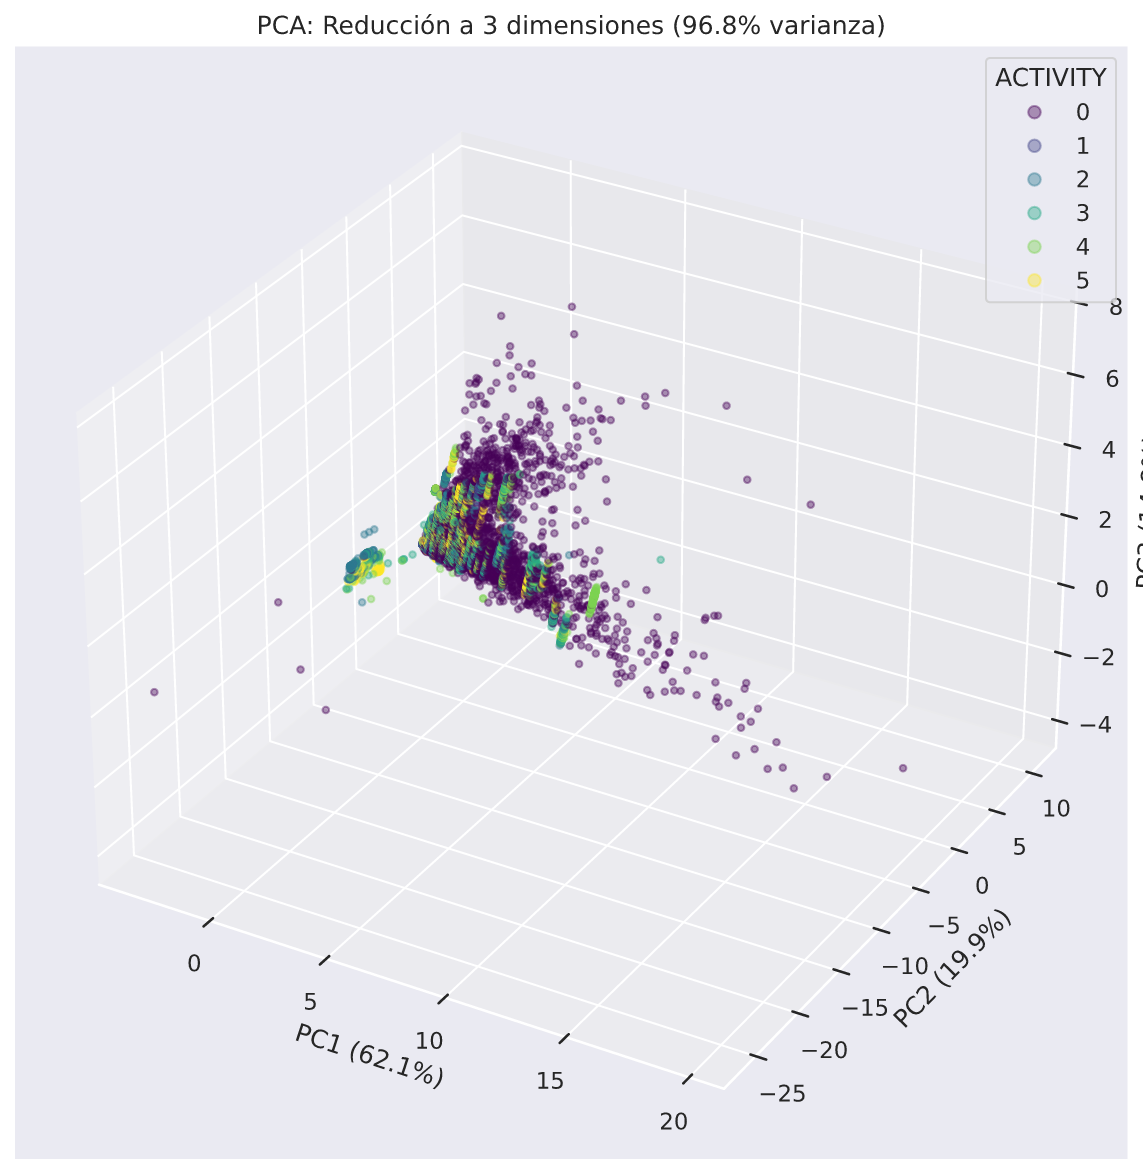

In [12]:
from mpl_toolkits.mplot3d import Axes3D

pca_3d = PCA(n_components=3)
X_pca3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_pca3d[:, 0], X_pca3d[:, 1], X_pca3d[:, 2],
                     c=y, cmap='viridis', alpha=0.4, s=10)
ax.set_xlabel('PC1 (%.1f%%)' % (100*pca_3d.explained_variance_ratio_[0]))
ax.set_ylabel('PC2 (%.1f%%)' % (100*pca_3d.explained_variance_ratio_[1]))
ax.set_zlabel('PC3 (%.1f%%)' % (100*pca_3d.explained_variance_ratio_[2]))
ax.set_title('PCA: Reducción a 3 dimensiones (%.1f%% varianza)' % (100*pca_3d.explained_variance_ratio_.sum()))
plt.legend(*scatter.legend_elements(), title='ACTIVITY')
plt.tight_layout()
plt.show()

## 4. t-SNE — t-Distributed Stochastic Neighbor Embedding

A diferencia de PCA, t-SNE es una técnica no lineal que se enfoca en preservar las distancias locales entre puntos. Como vimos en la Práctica 5 Adicional 1, t-SNE suele producir mejores visualizaciones cuando los datos no son linealmente separables, pero es más lenta y depende del hiperparámetro perplexity.

### 4.1 t-SNE en 2D (perplexity=30)

Empezamos con la configuración por defecto de perplexity=30, que es la misma que usamos en el notebook 2 de visualización.

In [13]:
from sklearn.manifold import TSNE

In [14]:
%%time
tsne_2d = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
X_tsne2d = tsne_2d.fit_transform(X_scaled)

CPU times: user 3min 2s, sys: 366 ms, total: 3min 3s
Wall time: 3min 36s


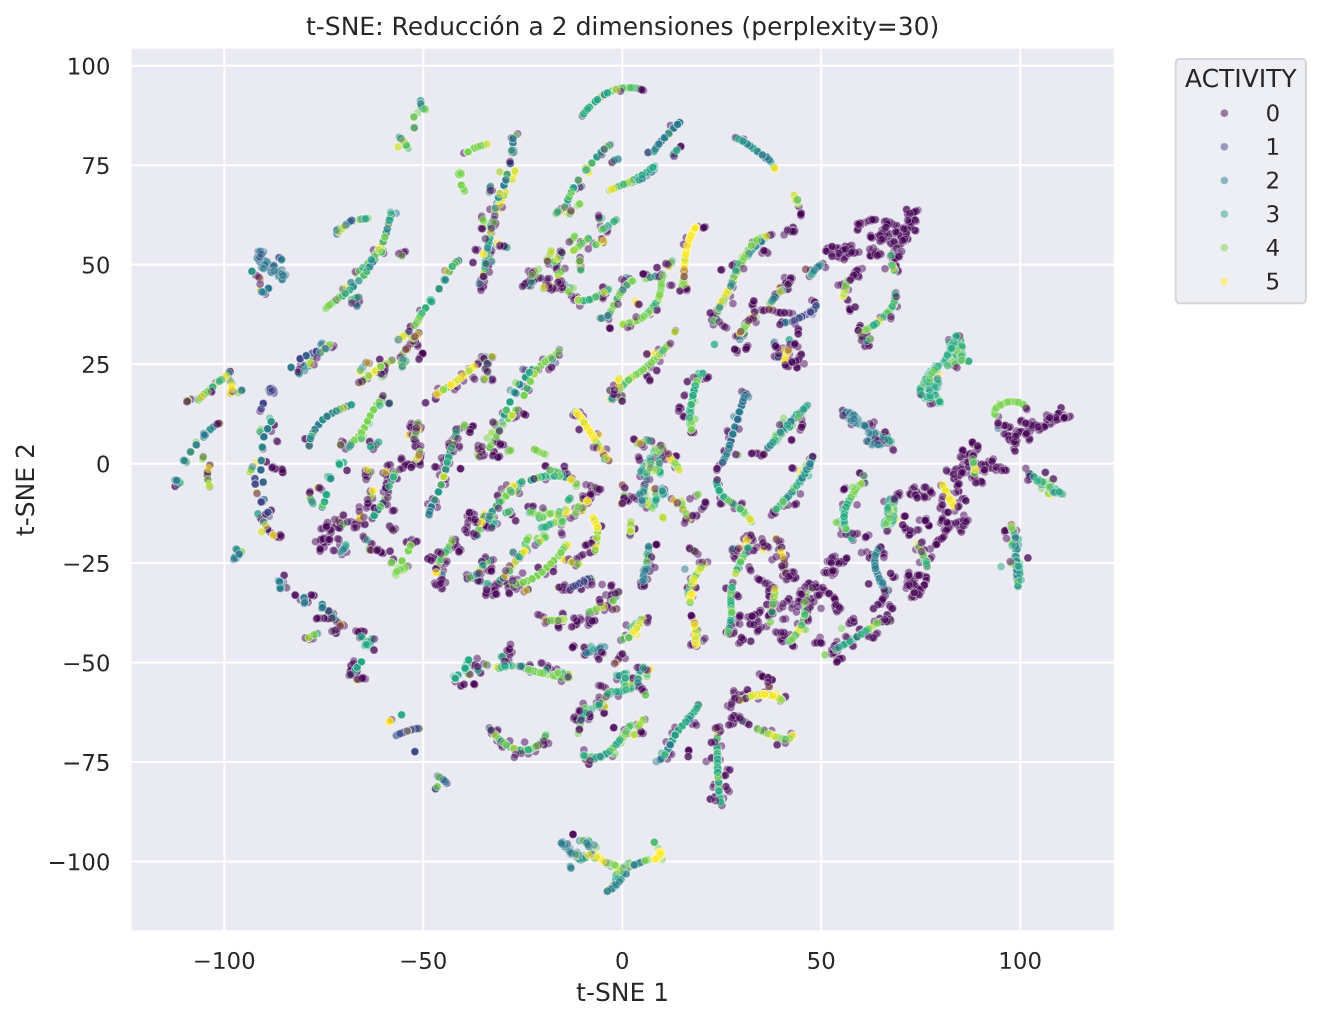

In [15]:
tsne_df = pd.DataFrame({'TSNE1': X_tsne2d[:, 0], 'TSNE2': X_tsne2d[:, 1], 'ACTIVITY': y})

plt.figure(figsize=(9, 7))
sns.scatterplot(x='TSNE1', y='TSNE2', hue='ACTIVITY', data=tsne_df, palette='viridis', alpha=0.5, s=15)
plt.title('t-SNE: Reducción a 2 dimensiones (perplexity=30)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(title='ACTIVITY', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

A diferencia del PCA 2D, t-SNE forma pequeños grupos locales con forma de "gusano" repartidos por todo el espacio. Se ve que la clase 0 tiende a agruparse en zonas propias, pero las clases 3, 4 y 5 siguen completamente mezcladas, igual que vimos en el notebook 2 de visualización.

### 4.2 Efecto de la perplexity

La perplexity controla cuántos vecinos considera t-SNE al construir la distribución de probabilidad. Valores bajos enfatizan la estructura local (clusters pequeños) y valores altos la estructura global. Probamos varios valores para ver cómo afecta a la visualización.

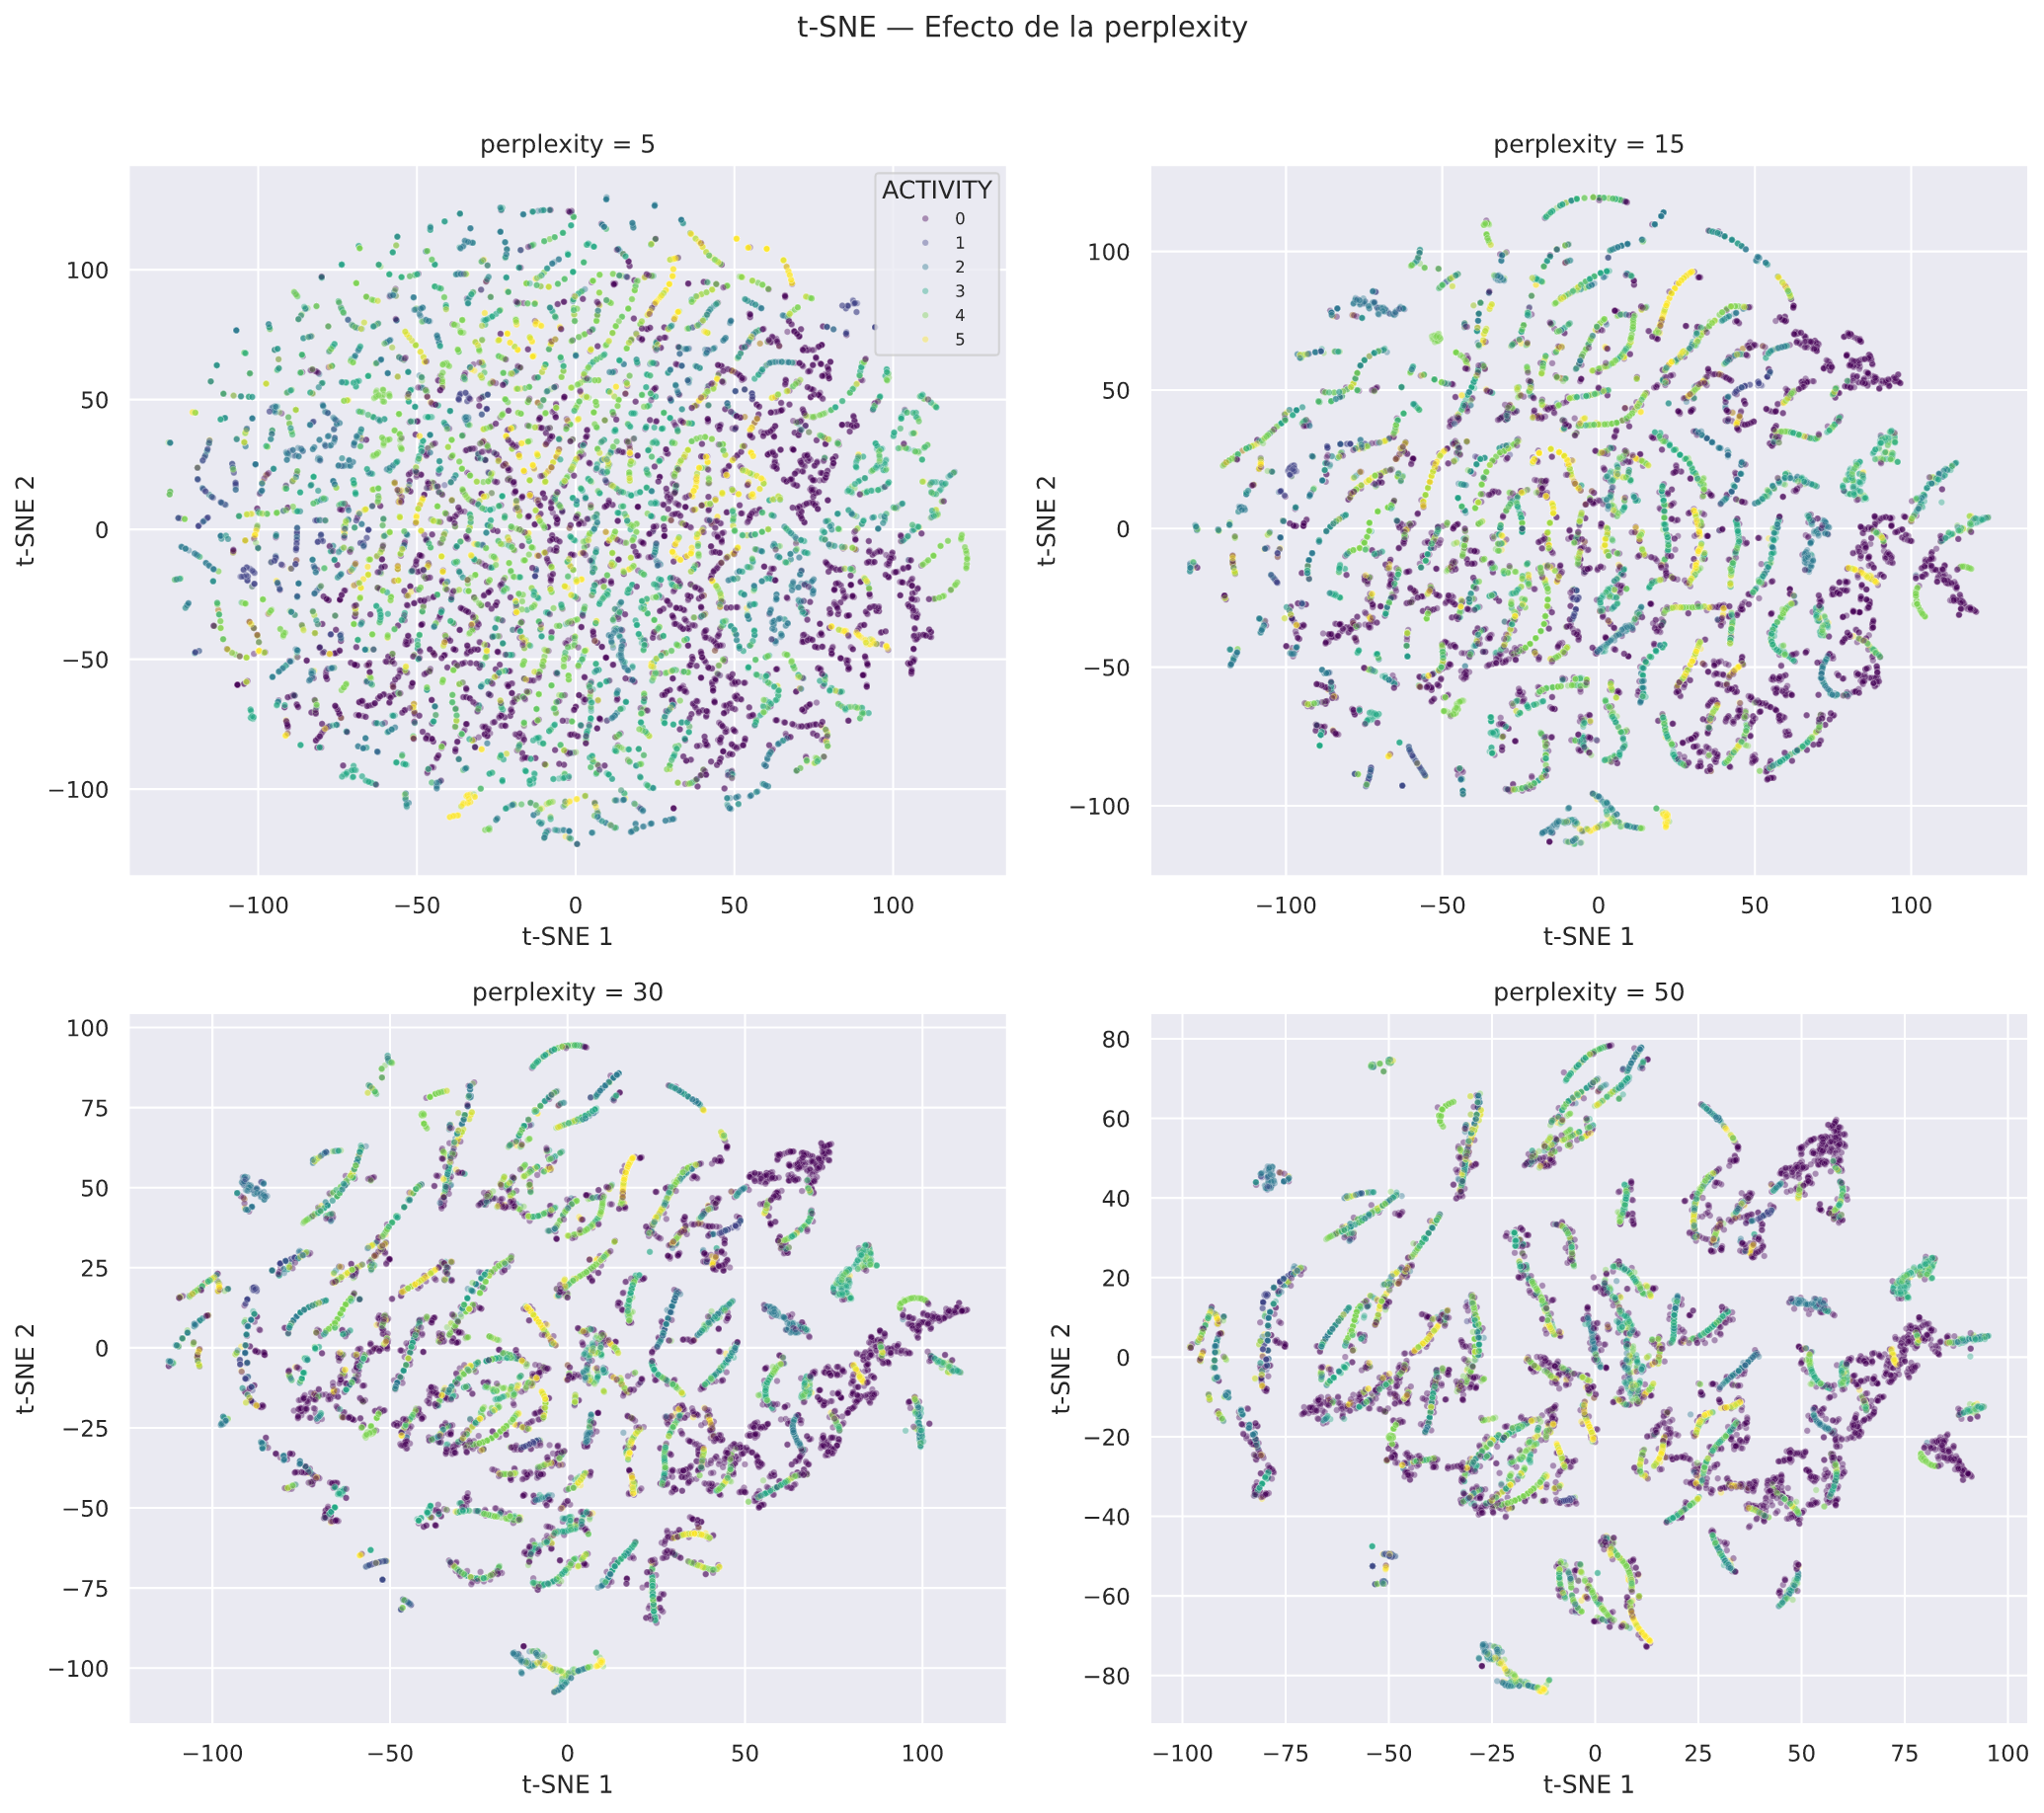

In [17]:
perplexities = [5, 15, 30, 50]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for i, perp in enumerate(perplexities):
    tsne_p = TSNE(n_components=2, random_state=42, perplexity=perp, n_iter=1000)
    X_proj = tsne_p.fit_transform(X_scaled)

    proj_df = pd.DataFrame({'D1': X_proj[:, 0], 'D2': X_proj[:, 1], 'ACTIVITY': y})
    ax = axes[i]
    sns.scatterplot(x='D1', y='D2', hue='ACTIVITY', data=proj_df, palette='viridis',
                    alpha=0.4, s=10, ax=ax, legend=(i == 0))
    ax.set_title('perplexity = %d' % perp)
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')

if axes[0].get_legend():
    axes[0].legend(title='ACTIVITY', fontsize=8)
plt.suptitle('t-SNE — Efecto de la perplexity', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Con perplexity=5 los puntos se dispersan sin estructura clara. A medida que subimos a 15, 30 y 50, los grupos se consolidan en filamentos más definidos, pero el patrón general no cambia: las clases 2–5 permanecen mezcladas independientemente del valor de perplexity. Esto confirma que el solapamiento es real y no un artefacto del hiperparámetro.

### 4.3 t-SNE en 3D

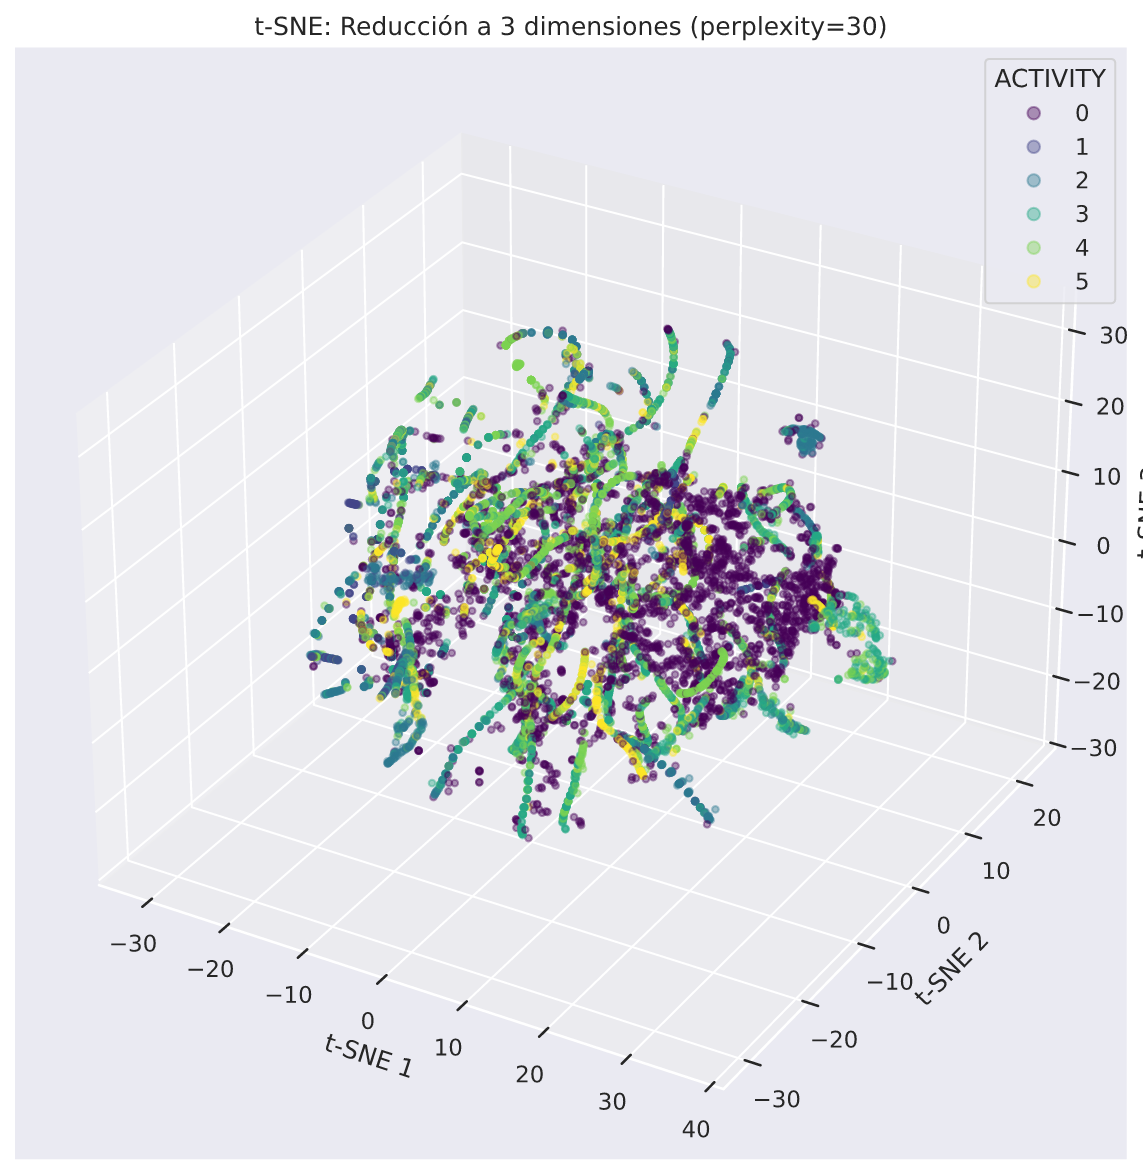

In [18]:
tsne_3d = TSNE(n_components=3, random_state=42, perplexity=30, n_iter=1000)
X_tsne3d = tsne_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_tsne3d[:, 0], X_tsne3d[:, 1], X_tsne3d[:, 2],
                     c=y, cmap='viridis', alpha=0.4, s=10)
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
ax.set_zlabel('t-SNE 3')
ax.set_title('t-SNE: Reducción a 3 dimensiones (perplexity=30)')
plt.legend(*scatter.legend_elements(), title='ACTIVITY')
plt.tight_layout()
plt.show()

La versión 3D de t-SNE ofrece una mejor separación visual que la 2D. La clase 0 se aísla y se pueden apreciar algunas agrupaciones parciales en el resto de clases. Sin embargo, t-SNE en 3D es significativamente más lento que en 2D y la mejora visual no es proporcional al coste computacional.

## 5. UMAP — Uniform Manifold Approximation and Projection

UMAP es una técnica más reciente que combina las ventajas de PCA (rapidez, preservación de la estructura global) y t-SNE (capacidad de capturar relaciones no lineales). Además, es mucho más rápido que t-SNE para datasets grandes.

In [19]:
!pip install -q umap-learn

In [20]:
import umap

In [21]:
%%time
reducer = umap.UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.1)
X_umap = reducer.fit_transform(X_scaled)

CPU times: user 47.9 s, sys: 1.23 s, total: 49.1 s
Wall time: 1min 3s


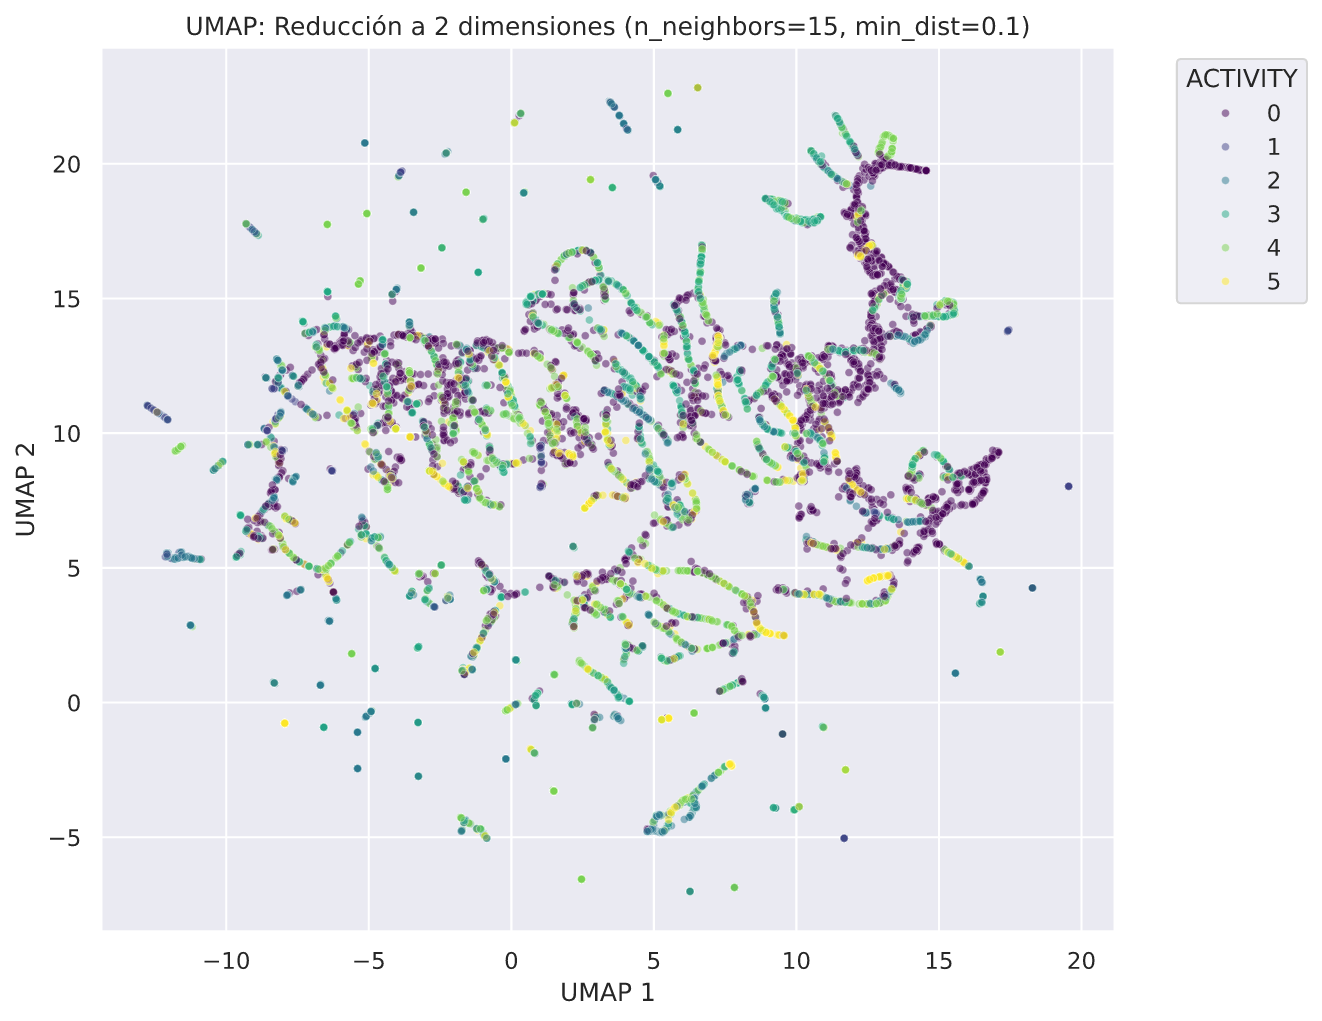

In [24]:
umap_df = pd.DataFrame({'UMAP1': X_umap[:, 0], 'UMAP2': X_umap[:, 1], 'ACTIVITY': y})

plt.figure(figsize=(9, 7))
sns.scatterplot(x='UMAP1', y='UMAP2', hue='ACTIVITY', data=umap_df, palette='viridis', alpha=0.5, s=15)
plt.title('UMAP: Reducción a 2 dimensiones (n_neighbors=15, min_dist=0.1)')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.legend(title='ACTIVITY', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

UMAP concentra la clase 0 en la esquina superior derecha, separándola mejor que t-SNE. También se intuye cierta agrupación de la clase 2 hacia la izquierda. Sin embargo, las clases 3, 4 y 5 siguen entrelazadas en la zona central, confirmando una vez más que el solapamiento entre estas clases

## 6. Conclusiones

La reducción de dimensionalidad aplicada a nuestro dataset confirma y amplía las conclusiones de los notebooks anteriores:

* La clase 0 es claramente separable en todas las técnicas. Sus valores extremos en SL, HR y CIRCULATION la distinguen del resto, lo que explica su alto recall (96.5%) con Random Forest en el notebook de análisis estadístico.

* Las clases 2, 3, 4 y 5 están fuertemente solapadas independientemente de la técnica utilizada.

* PCA es útil como primera aproximación rápida y para analizar la varianza, igual que en la Práctica 4 Parte 3. Pero al ser lineal no captura la estructura no lineal del problema. Esto es coherente con que los clasificadores lineales (LR, SVM lineal, Perceptrón) obtuvieron accuracy < 0.32 en el notebook de comparativa.

* t-SNE mejora la visualización pero es sensible al hiperparámetro perplexity y es costosa.

* UMAP es la técnica más equilibrada, es rápida como PCA, capaz de capturar relaciones no lineales como t-SNE, y produce clusters más compactos y separados.

Ninguna técnica consigue separar completamente las clases, lo que justifica que incluso nuestro mejor modelo (Random Forest optimizado) se quede en un accuracy de 0.76.